## Imports and plotting settings


In [1]:
import matplotlib as mpl
import matplotlib.gridspec as gridspec
import numpy as np
import xarray as xr
from matplotlib import pyplot as plt
from matplotlib import rcParams
import geopandas as gpd
rcParams.update({'figure.autolayout': False})
#import pymannkendall as mk
from cartopy import crs as ccrs
from cartopy.feature import ShapelyFeature
from cartopy.io.shapereader import Reader
from cartopy.mpl.gridliner import LATITUDE_FORMATTER, LONGITUDE_FORMATTER
import dask
import rioxarray
from dask.distributed import Client
from dask_jobqueue import PBSCluster
import calendar
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42

## Dask cluster on Casper


In [2]:
cluster = PBSCluster(
    cores=6,  
    memory='100GB',  
    processes=6,  
    queue='casper', 
    local_directory='/glade/derecho/scratch/adixit/tmp/',  
    resource_spec='select=1:ncpus=6:mem=100GB',  
    account='UCOR0105',  
    walltime='3:00:00', 
)

cluster.scale(jobs=1) 
client = Client(cluster)

In [4]:
client

<Client: 'tcp://128.117.208.191:39969' processes=6 threads=6, memory=93.12 GiB>

## ERA5

### Load and prepare temperature data


In [5]:
ds = xr.open_mfdataset('/glade/derecho/scratch/adixit/India_Heatwave/DATA/era5_data/era5.tmax.1940-2024.nc')
ds = ds.sel(longitude=slice(55,110), latitude=slice(45,5), time=slice('1950-01-01','2024-12-31'))-273.15
ds = ds.chunk(chunks={'time':-1,'longitude':50,'latitude':50})
ds = dask.compute(ds)[0]

### Trend and map functions


In [6]:
def calc_trend(ds,roll_w):
    ds = ds[list(ds.data_vars)[0]]
    ds = ds.rolling(time=roll_w).mean('time').dropna('time')
    from scipy.stats import t
    factor = 365 * 24 * 3600 * 1e9 * 10
    fit = ds.polyfit('time', 1, cov=True)
    slope = fit.polyfit_coefficients.sel(degree=1)
    se = np.sqrt(fit.polyfit_covariance.sel(cov_i=0, cov_j=0))
    pval = xr.apply_ufunc(lambda x: 2*t.sf(np.abs(x), ds.sizes['time']-2), slope/se)
    return slope * factor, pval

In [7]:
def plot_simulated(llon,llat,prec,row,col,levs,cmap1,shape_feature,ax1,ds_sig=None):
    #plt.style.use('classic')
    #plt.title(title)
    #ax1.("Y - axis")
    s=ax1.axes
    g=s.gridlines()
    g.bottom_labels=False
    g.left_labels=True

    if row == 0:
        g.bottom_labels=False
    if col>0:
        g.left_labels=True
    g.ylines=False
    g.xlines=False
    #g.xlocator = mticker.FixedLocator(np.arange(-115,-99,7))
    #g.ylocator = mticker.FixedLocator(np.arange(30,50,5))
    g.xformatter = LONGITUDE_FORMATTER
    g.yformatter = LATITUDE_FORMATTER
    g.xlabel_style = {'size':7.5, 'color': 'k'}
    g.ylabel_style = {'size': 7.5, 'color': 'k'}  
    pc1 = plt.contourf(llon,llat,prec,cmap=cmap1,transform=ccrs.PlateCarree(), levels=levs, extend='both')   
    #pc1 = plt.contourf(llon,llat,prec,colors=cmap1,transform=ccrs.PlateCarree(), levels=levs)   
    #fname = '/media/ankur/f764cec3-536e-4e1d-b58c-9442c881e0a0/ankur/VIC_DATA/BasinBoundary/Beas.shp'
    
    ax1.add_feature(shape_feature)
    if ds_sig is not None:
        plt.rcParams['hatch.linewidth'] = 0.65
        cs = ax1.contourf(ds_sig.longitude, ds_sig.latitude, ds_sig.astype(int),
                 levels=[0.5, 1.5], colors='none', hatches=['....'],
                 transform=ccrs.PlateCarree())
        for c in cs.collections:
            c.set_edgecolor('#525252')  # Hatch color
            c.set_linewidth(0)      # Hatch line thickness
    return pc1


### India boundary and month labels


In [8]:
shp_file = '/glade/derecho/scratch/adixit/India_Heatwave/shapefiles/india_st.shp'
shape_feature = ShapelyFeature(Reader(shp_file).geometries(), ccrs.PlateCarree(),edgecolor='black', facecolor='none',lw=0.5)

### May and June trend maps


<xarray.DataArray 'polyfit_coefficients' ()> Size: 8B
array(-0.0875222)
Coordinates:
    degree   int64 8B 1
<xarray.DataArray 'polyfit_coefficients' ()> Size: 8B
array(-0.06138597)
Coordinates:
    degree   int64 8B 1


Text(0.5, 1.0, '˚C/decade')

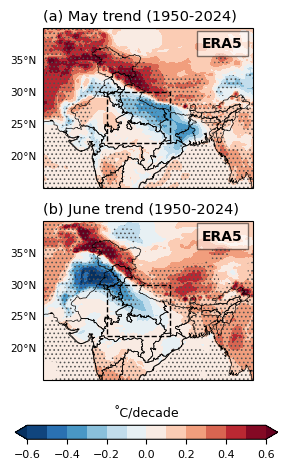

In [10]:
import warnings
import matplotlib.patches as patches
warnings.filterwarnings("ignore", category=DeprecationWarning)

f = plt.figure(figsize=(3.5,5))
gs1 = gridspec.GridSpec(2, 1)
gs1.update(left=0.25, right=0.85, bottom=0.2, top=0.92, hspace=0.15)


ttls = ['(a) May trend (1950-2024)','(b) June trend (1950-2024)']

cmap1 = 'RdBu_r'
levs = np.arange(-0.6, 0.61, 0.1)

months_to_plot = [5, 6]   # May, June

for idx, m in enumerate(months_to_plot):

    ax1 = f.add_subplot(gs1[idx, 0], projection=ccrs.PlateCarree())
    ax1.coastlines(resolution='50m', linewidth=0.5, color='black')
    data,_ = calc_trend(ds.sel(time=ds.time.dt.month == m).resample(time='YS').mean(),roll_w=10)
    _,pval = calc_trend(ds.sel(time=ds.time.dt.month == m).resample(time='YS').mean(),roll_w=1)
    pc = plot_simulated(data.longitude, data.latitude, data,0, idx, levs, cmap1, shape_feature, ax1, ds_sig=pval<0.05)

    ax1.text(0.95, 0.95, 'ERA5',transform=ax1.transAxes, fontsize=10,fontweight='bold', ha='right', va='top',
        bbox=dict(facecolor='white', alpha=0.5, edgecolor='black'))
    
    #rectangle1 = patches.Rectangle((67, 22), 15, 8, edgecolor='k', facecolor='None', linewidth=1, linestyle='--')
    rectangle1 = patches.Rectangle((75, 22), 10, 8, edgecolor='k', facecolor='None', linewidth=1, linestyle='--')
    ax1.add_patch(rectangle1)
    #ax1.set_xlim([67.5,97.5])
    #ax1.set_ylim([7.5,37.5])
    ax1.set_xlim([65,98])
    ax1.set_ylim([15,40])
    box_lon = slice(75, 85)
    box_lat = slice(30, 22)
    box_mean = data.sel(longitude=box_lon, latitude=box_lat).mean()
    print(box_mean.compute())
    box_trend = np.round(box_mean.compute().item(),2)
    #ax1.text(0.65,0.63,'(   %s \n˚C/decade)' %(box_trend),transform=ax1.transAxes, fontsize=9)#,fontweight='bold')
    ax1.set_title(ttls[idx],fontsize=10.5,loc='left')


#plt.suptitle("MaxT Trends in ERA5: May & June (1950–2024)")

cbar_ax = f.add_axes([0.17, 0.09, 0.75, 0.028])
cb = plt.colorbar(pc, cax=cbar_ax, orientation="horizontal")
cb.ax.tick_params(labelsize=8)
cb.ax.set_title('˚C/decade', fontsize=9)
#plt.savefig("ERA5-T2max_trend.pdf",dpi=300,format='pdf',transparent=True)

## IMD


### Load temperature and boundary data


In [11]:
ds = xr.open_dataset('/glade/derecho/scratch/adixit/India_Heatwave/DATA/Data/Maxtemp_MaxT_1951-2023.nc')
shp_file = '/glade/derecho/scratch/adixit/India_Heatwave/shapefiles/india_st.shp'
gdf_india = gpd.read_file(shp_file)

### Trend function


In [12]:
def calc_trend(ds,roll_w):
    ds = ds[list(ds.data_vars)[0]]
    ds = ds.rolling(time=roll_w).mean('time').dropna('time')
    from scipy.stats import t
    factor = 365 * 24 * 3600 * 1e9 * 10
    fit = ds.polyfit('time', 1, cov=True)
    slope = fit.polyfit_coefficients.sel(degree=1)
    se = np.sqrt(fit.polyfit_covariance.sel(cov_i=0, cov_j=0))
    pval = xr.apply_ufunc(lambda x: 2*t.sf(np.abs(x), ds.sizes['time']-2), slope/se)
    return slope * factor, pval

### May and June trend maps


Text(0.5, 1.0, '˚C/decade')

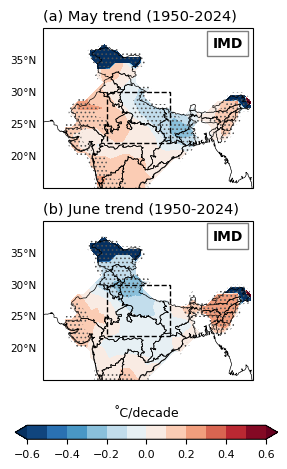

In [14]:
warnings.filterwarnings("ignore", category=DeprecationWarning)

f = plt.figure(figsize=(3.5,5))
gs1 = gridspec.GridSpec(2, 1)
gs1.update(left=0.25, right=0.85, bottom=0.2, top=0.92, hspace=0.15)


ttls = ['(a) May trend (1950-2024)','(b) June trend (1950-2024)']

cmap1 = 'RdBu_r'
levs = np.arange(-0.6, 0.61, 0.1)

months_to_plot = [5, 6]   # May, June

for idx, m in enumerate(months_to_plot):

    ax1 = f.add_subplot(gs1[idx, 0], projection=ccrs.PlateCarree())
    ax1.coastlines(resolution='50m', linewidth=0.5, color='black')
    data,_ = calc_trend(ds.sel(time=ds.time.dt.month == m).resample(time='YS').mean(),roll_w=10)
    _,pval = calc_trend(ds.sel(time=ds.time.dt.month == m).resample(time='YS').mean(),roll_w=1)

    data = data.rio.write_crs("EPSG:4326")       
    pval = pval.rio.write_crs("EPSG:4326")
    #data = data.rio.set_spatial_dims(x_dim="lon", y_dim="lat")  

    data = data.rio.clip(gdf_india.geometry, gdf_india.crs, drop=True,all_touched=True)  
    #pval = pval.sel(latitude=data.latitude, longitude=data.longitude)
    pval = pval.rio.clip(gdf_india.geometry, gdf_india.crs, drop=True,all_touched=True)
    pc = plot_simulated(data.longitude, data.latitude, data,0, idx, levs, cmap1, shape_feature, ax1,ds_sig=pval<0.05)

    ax1.text(0.95, 0.95, 'IMD',transform=ax1.transAxes, fontsize=10,fontweight='bold', ha='right', va='top',
        bbox=dict(facecolor='white', alpha=0.5, edgecolor='black'))
    
    #rectangle1 = patches.Rectangle((67, 22), 15, 8, edgecolor='k', facecolor='None', linewidth=1, linestyle='--')
    rectangle1 = patches.Rectangle((75, 22), 10, 8, edgecolor='k', facecolor='None', linewidth=1, linestyle='--')
    ax1.add_patch(rectangle1)
    #ax1.set_xlim([67.5,97.5])
    #ax1.set_ylim([7.5,37.5])
    ax1.set_xlim([65,98])
    ax1.set_ylim([15,40])
    box_lon = slice(75, 85)
    box_lat = slice(30, 22)
    box_mean = data.sel(longitude=box_lon, latitude=box_lat).mean()
    #print(box_mean.compute())
    box_trend = np.round(box_mean.compute().item(),2)
    #ax1.text(0.65,0.63,'(   %s \n˚C/decade)' %(box_trend),transform=ax1.transAxes, fontsize=9)#,fontweight='bold')
    ax1.set_title(ttls[idx],fontsize=10.5,loc='left')


#plt.suptitle("MaxT Trends in ERA5: May & June (1950–2024)")

cbar_ax = f.add_axes([0.17, 0.09, 0.75, 0.028])
cb = plt.colorbar(pc, cax=cbar_ax, orientation="horizontal")
cb.ax.tick_params(labelsize=8)
cb.ax.set_title('˚C/decade', fontsize=9)
#plt.savefig("IMD-T2max_trend.pdf",dpi=300,format='pdf',transparent=True)

## CESM2 Large Ensemble

### Load and prepare ensemble mean temperature


In [15]:
ds = xr.open_mfdataset('/glade/derecho/scratch/adixit/India_Heatwave/DATA/cesm2le/CESM2-LE.tmax.1850-2100.nc')
ds_anom = ds['TREFHTMX'].mean(dim='lemem')
ds = ds_anom.sel(lon=slice(55,110), lat=slice(5,45), time=slice('1950-01-01','2024-12-31'))-273.15
ds = dask.compute(ds)[0]
ds = ds.rename({'lat':'latitude','lon':'longitude'})

### Trend and map functions


In [16]:
def calc_trend(ds,roll_w):
    #ds = ds[list(ds.data_vars)[0]]
    ds = ds.rolling(time=roll_w).mean('time').dropna('time')
    from scipy.stats import t
    factor = 365.2425 * 24 * 3600 * 1e9 * 10
    fit = ds.polyfit('time', 1, cov=True)
    slope = fit.polyfit_coefficients.sel(degree=1)
    se = np.sqrt(fit.polyfit_covariance.sel(cov_i=0, cov_j=0))
    pval = xr.apply_ufunc(lambda x: 2*t.sf(np.abs(x), ds.sizes['time']-2), slope/se)
    return slope * factor, pval

In [17]:
def plot_simulated(llon,llat,prec,row,col,levs,cmap1,shape_feature,ax1,ds_sig=None):
    #plt.style.use('classic')
    #plt.title(title)
    #ax1.("Y - axis")
    s=ax1.axes
    g=s.gridlines()
    g.bottom_labels=False
    g.left_labels=True

    if row == 0:
        g.bottom_labels=False
    if col>0:
        g.left_labels=True
    g.ylines=False
    g.xlines=False
    #g.xlocator = mticker.FixedLocator(np.arange(-115,-99,7))
    #g.ylocator = mticker.FixedLocator(np.arange(30,50,5))
    g.xformatter = LONGITUDE_FORMATTER
    g.yformatter = LATITUDE_FORMATTER
    g.xlabel_style = {'size':7.5, 'color': 'k'}
    g.ylabel_style = {'size': 7.5, 'color': 'k'}  
    pc1 = plt.contourf(llon,llat,prec,cmap=cmap1,transform=ccrs.PlateCarree(), levels=levs, extend='both')   
    #pc1 = plt.contourf(llon,llat,prec,colors=cmap1,transform=ccrs.PlateCarree(), levels=levs)   
    #fname = '/media/ankur/f764cec3-536e-4e1d-b58c-9442c881e0a0/ankur/VIC_DATA/BasinBoundary/Beas.shp'
    
    ax1.add_feature(shape_feature)
    if ds_sig is not None:
        plt.rcParams['hatch.linewidth'] = 0.35
        cs = ax1.contourf(ds_sig.longitude, ds_sig.latitude, ds_sig.astype(int),
                 levels=[0.5, 1.5], colors='none', hatches=['....'],
                 transform=ccrs.PlateCarree())
        for c in cs.collections:
            c.set_edgecolor('#525252')  # Hatch color
            c.set_linewidth(0)      # Hatch line thickness
    return pc1


### India boundary


In [18]:
shp_file = '/glade/derecho/scratch/adixit/India_Heatwave/shapefiles/india_st.shp'
shape_feature = ShapelyFeature(Reader(shp_file).geometries(), ccrs.PlateCarree(),edgecolor='black', facecolor='none',lw=0.5)

### May and June trend maps


Text(0.5, 1.0, '˚C/decade')

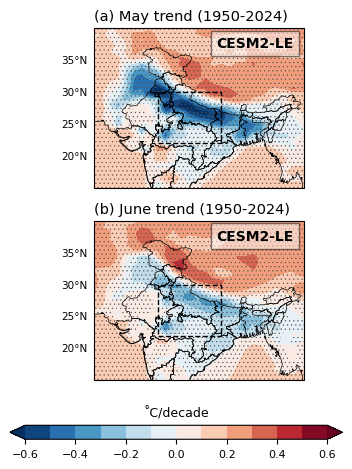

In [20]:
warnings.filterwarnings("ignore", category=DeprecationWarning)

f = plt.figure(figsize=(3.5,5))
gs1 = gridspec.GridSpec(2, 1)
gs1.update(left=0.25, right=0.85, bottom=0.2, top=0.92, hspace=0.15)


ttls = ['(a) May trend (1950-2024)','(b) June trend (1950-2024)']

cmap1 = 'RdBu_r'
levs = np.arange(-0.6, 0.61, 0.1)

months_to_plot = [5, 6]   # May, June

for idx, m in enumerate(months_to_plot):

    ax1 = f.add_subplot(gs1[idx, 0], projection=ccrs.PlateCarree())
    ax1.coastlines(resolution='50m', linewidth=0.5, color='black')
    data,_ = calc_trend(ds.sel(time=ds.time.dt.month == m).resample(time='YS').mean(),roll_w=10)
    _,pval = calc_trend(ds.sel(time=ds.time.dt.month == m).resample(time='YS').mean(),roll_w=1)
    pc = plot_simulated(data.longitude, data.latitude, data,0, idx, levs, cmap1, shape_feature, ax1,ds_sig=pval<0.05)

    ax1.text(0.95, 0.95, 'CESM2-LE',transform=ax1.transAxes, fontsize=10,fontweight='bold', ha='right', va='top',
        bbox=dict(facecolor='white', alpha=0.5, edgecolor='black'))
    
    #rectangle1 = patches.Rectangle((67, 22), 15, 8, edgecolor='k', facecolor='None', linewidth=1, linestyle='--')
    rectangle1 = patches.Rectangle((75, 22), 10, 8, edgecolor='k', facecolor='None', linewidth=1, linestyle='--')
    ax1.add_patch(rectangle1)
    #ax1.set_xlim([67.5,97.5])
    #ax1.set_ylim([7.5,37.5])
    ax1.set_xlim([65,98])
    ax1.set_ylim([15,40])
    box_lon = slice(75, 85)
    box_lat = slice(30, 22)
    box_mean = data.sel(longitude=box_lon, latitude=box_lat).mean()
    box_trend = np.round(box_mean.compute().item(),2)
    #ax1.text(0.65,0.63,'(   %s \n˚C/decade)' %(box_trend),transform=ax1.transAxes, fontsize=9)#,fontweight='bold')
    ax1.set_title(ttls[idx],fontsize=10.5,loc='left')


#plt.suptitle("MaxT Trends in ERA5: May & June (1950–2024)")

cbar_ax = f.add_axes([0.01, 0.09, 0.95, 0.028])
cb = plt.colorbar(pc, cax=cbar_ax, orientation="horizontal")
cb.ax.tick_params(labelsize=8)
cb.ax.set_title('˚C/decade', fontsize=9)
#plt.savefig("CESM2LE-T2max_trend.pdf",dpi=300,format='pdf',transparent=True)